In [2]:
# Setup 
import torch 
import torch.nn.functional as f 
import matplotlib.pyplot as plt 
import random 
torch.manual_seed(19)


Preactivation: mean=-0.00, std=3.22
After tanh: mean=-0.00, std=0.87


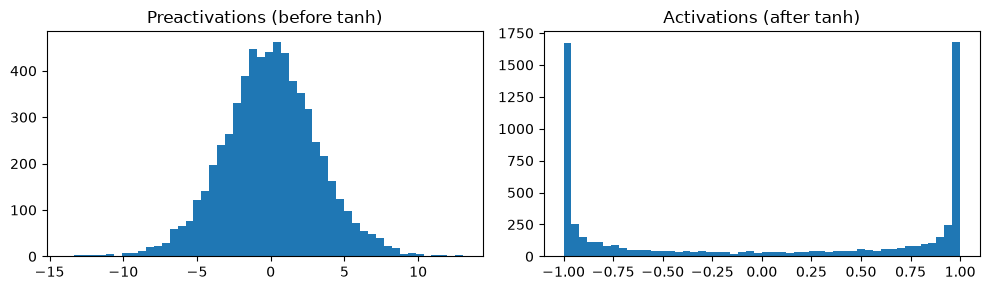

In [5]:
# imagine we have a hidden layer with tanh activation 
# i.e. if z = Xemb. @ w + b
# h = tanh(z) =  tanh(x @ w + b) = (e^z - e^-z)/(e^z + e^-z)

# So if W is to large  = then tanh will get saturated

x = torch.randn(32,10) # batch of 32 ( 32 different training examples are being passed through at once) and 
                       # a context of 2 characters with 5 dimensions = 10 input features 

w = torch.randn(10,200) # larger weight matrix (unscaled! )

b = torch.zeros(200) # create a matrix of 200 zeros , 
                    # By setting b = 0, you ensure the bias contributes zero offset at step 0

preactivation = x @ w + b  # Raw output before using activation functions tanh()

h = torch.tanh(preactivation) # Applying activation function tanh()


print(f"Preactivation: mean={preactivation.mean():.2f}, std={preactivation.std():.2f}")
print(f"After tanh: mean={h.mean():.2f}, std={h.std():.2f}")


# Plot distribution of activations
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(preactivation.view(-1).detach().numpy(), bins=50)
plt.title("Preactivations (before tanh)")
plt.subplot(1, 2, 2)
plt.hist(h.view(-1).detach().numpy(), bins=50)
plt.title("Activations (after tanh)")
plt.tight_layout()
plt.show()




### Visualizing Dead Neurons 

In [ ]:
# CELL 2 — How many neurons are "dead" (saturated)?
# A neuron is "dead" if |tanh output| > 0.99
dead_fraction = (h.abs() > 0.99).float().mean()
# steps 
# Step - 1 : abs : caluclate abosolte value ex. -0.23x as + 0.23x
# Step 2 : >0.99(healthy neorons )
# Step. 3 : 1 for true and 0 for false 
# Step 4 : .mean() , no. of true/(total = 32*200 = 6400)


print(f"Fraction of dead neurons: {dead_fraction:.2%}")

# With random init: often 50-80% of neurons are dead at step 0!
# This means the network starts in a BAD state.

Fraction of dead neurons: 38.50%


## FIX - 01 : Proper weight initialization 

### The Goal : Mean = 0 and std = 1.0(close to 1 )

* We want preactivations to be spread around 0.
* Then tanh maps most values to the linear region (not saturated).
* Gradients flow freely. Learning happens.

### Key insight:
#### If input x has std=1 and we multiply by W (std=1)and W has shape (fan_in, fan_out):

#### → output std = sqrt(fan_in) (gets larger!)
#### → To keep std=1 → divide W by sqrt(fan_in) $$W = \frac{W}{\sqrt{\text{fan\_in}}}$$


In [7]:
# FIX : Scale W = w/ sqrt(fan_in )

x = torch.randn(32,10)
w_fixed = torch.randn(10,200) / (10 ** 0.5) # W = w/ sqrt(fan_in )# as fan_in = 10 .
b = torch.zeros(200)

preactivation_fixed = x @ w_fixed + b 
h_fixed = torch.tanh(preactivation_fixed)

print(f"Fixed preactivation: mean={preactivation_fixed.mean():.2f}, std={preactivation_fixed.std():.2f}")

print(f"Fixed after tanh: mean={h_fixed.mean():.2f}, std={h_fixed.std():.2f}")

Fixed preactivation: mean=0.00, std=1.09
Fixed after tanh: mean=0.01, std=0.64


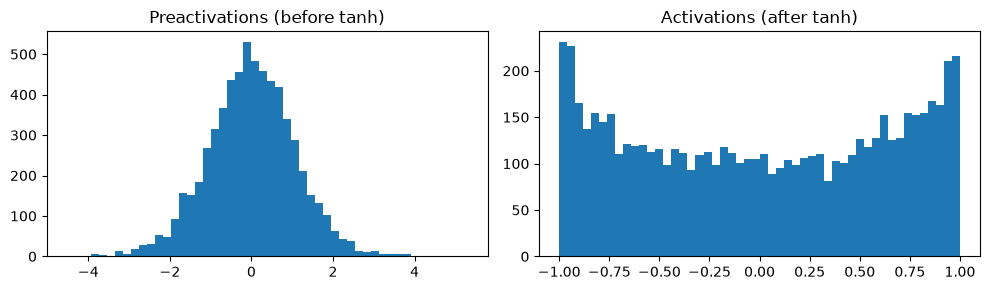

In [8]:
# Plot distribution of activations
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(preactivation_fixed.view(-1).detach().numpy(), bins=50)
plt.title("Preactivations (before tanh)")
plt.subplot(1, 2, 2)
plt.hist(h_fixed.view(-1).detach().numpy(), bins=50)
plt.title("Activations (after tanh)")
plt.tight_layout()
plt.show()

In [9]:
dead_fraction_fixed = (h_fixed.abs() > 0.99).float().mean()
print(f"Dead neurons after fix: {dead_fraction_fixed:.2%}")

Dead neurons after fix: 2.14%


* The squashing effect: Because $\tanh$ contracts numbers toward $0$ (unlike a straight line $y = x$), it shrinks the standard deviation. If you only divide by $\sqrt{\text{fan\_in}}$, the spread after $\tanh$ drops below $1.0$ (down to around $0.62$–$0.65$).

## Kaiming (HE) Initilization - The Industry Standard 

#### Kaiming initialization (used in PyTorch by default for ReLU)
#### For tanh activation:
#### gain = 5/3 (recommended by Karpathy / PyTorch docs)
#### For ReLU activation:
#### gain = sqrt(2)

In [10]:
fan_in = 10 
gain = 5/3 # for tanh

w_kaiming = torch.randn(10,200) * gain / (fan_in ** 0.5)

preactivation_kaiming = x @ w_kaiming + b 

h_kaiming = torch.tanh(preactivation_kaiming)

print(f"Kaiming preactivation: mean={preactivation_kaiming.mean():.2f}, std={preactivation_kaiming.std():.2f}")
print(f"Kaiming after tanh: mean={h_kaiming.mean():.2f}, std={h_kaiming.std():.2f}")

Kaiming preactivation: mean=0.02, std=1.78
Kaiming after tanh: mean=0.01, std=0.76


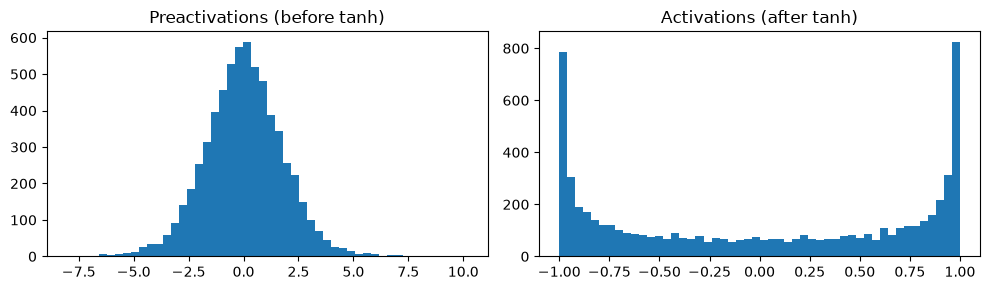

In [11]:
# Plot distribution of activations
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.hist(preactivation_kaiming.view(-1).detach().numpy(), bins=50)
plt.title("Preactivations (before tanh)")
plt.subplot(1, 2, 2)
plt.hist(h_kaiming.view(-1).detach().numpy(), bins=50)
plt.title("Activations (after tanh)")
plt.tight_layout()
plt.show()

In [13]:
dead_fraction_fixed = (h_kaiming.abs() > 0.99).float().mean()
print(f"Dead neurons after fix: {dead_fraction_fixed:.2%}")

Dead neurons after fix: 12.44%


##### Why We Accept More "Dead" ActivationsThe jump from $\sim 2\%$ to $\sim 12\%$ saturated activations is an intentional engineering trade-off between two opposing risks:  
#### Risk A: Vanishing Signal (Without Gain):
##### If you only scale weights by $\frac{1}{\sqrt{\text{fan\_in}}}$, post-$\tanh$ variance drops to $\sim 0.63$. Over a 10-layer network, variance shrinks exponentially:
*  $$(0.63)^{10} \approx 0.0098 \text{[cite: 2]}$$
##### Activations collapse toward zero, backpropagation receives negligible signal, and the entire network freezes.  
#### Risk B: Mild Saturation (With Gain):
##### Multiplying by $\frac{5}{3}$ keeps post-$\tanh$ standard deviation around $\sim 0.76\text{–}0.80$ across layers. Accepting a minor increase in saturated tails ensures the remaining $\sim 88\%\text{–}90\%$ of activations stay healthy enough to transmit learning signals through the network.     

##### WHAT YOU LEARN:
* The "magic number" for weight init:
* W = torch.randn(fan_in, fan_out) * gain / sqrt(fan_in)

* PyTorch uses this automatically in nn.Linear, nn.Conv2d
when you call: torch.nn.init.kaiming_normal_(W)

#### in Part 3, we spent time learning Kaiming Initialization. We carefully divided weights by $\sqrt{\text{fan\_in}}$ and multiplied by a gain factor so that activations started with a balanced mean of $0$ and standard deviation of roughly $1$.   
#### The Catch: Initialization only sets the starting position on step 0.  
####  What happens next: As soon as training begins, the optimizer modifies the weights ($W_{\text{new}} = W_{\text{old}} - \text{lr} \times \nabla W$) across every layer simultaneously.
#### The breakdown:When weights in Layer 1 change, the outputs going into Layer 2 change completely.When Layer 2's inputs change, its outputs shift as well.
#### Over 500 or 1,000 optimization steps, the numbers drift away from the initial balance.   Activations gradually grow too large or collapse, pushing neurons right back into the saturated, dead zones of $\tanh$. 

#### # This is the exact reason Batch Normalization (BatchNorm) was invented

# # Batch Normalization ( The main concept)

### What is Batch Normalization(BatchNorm)

#### 1. $$\text{Linear Layer} \longrightarrow \mathbf{\text{BatchNorm}} \longrightarrow \tanh \text{ Activation} \text{[cite: 7]}$$Whenever a batch of activations comes out of a linear layer, BatchNorm explicitly standardizes them so they always have $\text{mean} = 0$ and $\text{std} = 1$ before entering $\tanh$. Because values are bounded around $0$, inputs to $\tanh$ stay away from the flat saturation plateaus.

#### 2. The Big Dilemma: "Won't Forcing Numbers to Mean=0 and Std=1 Destroy Learning?"This is a subtle question:What if a specific neuron needs to fire with large positive values to detect a vowel?   What if another neuron needs to stay negative to signal a word boundary?   If we strictly force every neuron's output to have a mean of $0$ and spread of $1$, we risk stripping the network of its ability to learn expressive representations. 

----------------------------------------------------------------------------------------------------------------------------------------------------------

#### ## The Solution: The Learnable Parameters $\gamma$ (Scale) and $\beta$ (Shift)To prevent rigid constraints from limiting expressiveness, BatchNorm introduces two learnable parameters for each neuron:   $\gamma$ (gamma): Controls the scale (spread/standard deviation).$\beta$ (beta): Controls the shift (center/mean).  
#### This allows the network to "un-normalize" or adapt the distribution if training benefits from doing so.  
#### At the start of training: $\gamma = 1.0$ and $\beta = 0.0$. The activations begin strictly normalized ($\text{mean}=0, \text{std}=1$). 
####  During training: If backpropagation discovers that a neuron works better with a larger spread or a shifted mean, it updates $\gamma$ and $\beta$ through gradient descent.   
#### Crucially, this shift is now governed by two dedicated knobs per feature rather than by the tangled product of thousands of weight parameters

### 3. The 3 Steps of Batch Normalization

Batch Normalization (BatchNorm) processes a batch of activations in three sequential steps.

#### Step-by-Step Process

```text
Raw Linear Output (x)
         |
         v
+----------------------------------------------+
| STEP 1: Normalize                            |
| Subtract batch mean (μ_B)                    |
| Divide by batch standard deviation           |
|                                              |
| Result: Mean ≈ 0, Standard Deviation ≈ 1     |
+----------------------------------------------+
         |
         v
+----------------------------------------------+
| STEP 2: Scale by γ (Gamma)                   |
| Multiply by the learnable parameter γ        |
+----------------------------------------------+
         |
         v
+----------------------------------------------+
| STEP 3: Shift by β (Beta)                    |
| Add the learnable parameter β                |
+----------------------------------------------+
         |
         v
Output to Tanh: y = γ * x_hat + β
```

#### The Complete Formula

$$
y = \gamma \left(
\frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}
\right)+\beta
$$

#### Explanation of Each Term

- **`x`**: The raw pre-activation values coming from the linear layer.
- **`μ_B` (Batch Mean)**: The average of the activation values across the current mini-batch.
- **`σ_B²` (Batch Variance)**: Measures how spread out the activation values are across the current mini-batch.
- **`ε` (Epsilon)**: A small constant, typically `10⁻⁵`, added inside the square root to prevent division by zero and improve numerical stability.
- **`γ` (Gamma)**: A learnable scaling parameter, typically initialized to `1`. It controls the scale of the normalized activations.
- **`β` (Beta)**: A learnable shifting parameter, typically initialized to `0`. It controls the shift of the normalized activations.
- **`x_hat` (Normalized Activation)**: The activation after subtracting the batch mean and dividing by the adjusted standard deviation.

#### Mathematical Steps

**Step 1: Normalize**

$$
\hat{x}=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}
$$

**Step 2: Scale**

$$
z=\gamma\hat{x}
$$

**Step 3: Shift**

$$
y=z+\beta
$$

Therefore, the final output is:

$$
\boxed{y=\gamma\hat{x}+\beta}
$$

This output is then passed to the activation function, such as `tanh`, if BatchNorm is placed before that activation function.

#### Key Takeaway

Batch Normalization first normalizes activations, then scales them using `γ` and shifts them using `β`. The learnable parameters allow the neural network to adjust the normalized values to a distribution that helps it learn effectively.

In [16]:
# Batch Normalization (BatchNorms from scratch )

# Inputs: batch of activations (before tanh)
# Shape: (batch_size,num_features) e.g., (32, 200)

torch.manual_seed(19)
preactivation = torch.randn(32,200) # pretend these as a preactivations
# 32 independent training examples simultaneously, 200 (Columns): The number of neurons or features (D).

## Step 1: Compute mean and variance ACROSS THE BATCH (dim=0)

bn_mean = preactivation.mean(dim=0,keepdim=True)  # shape: (1, 200) # without keepdim = True , shape = [200,]
bn_var = preactivation.var(dim=0,keepdim=True)    # shape: (1, 200) # with keepdim = True , shape = [1,200]

##  Step 2 : Normalize

eps = 1e-5 # small number to avoid division by zero , eps = 1e-5 = eps = 0.00001
preactivation_norms = (preactivation - bn_mean)/ torch.sqrt(bn_var+eps)

# Now preact_norm has mean ~ 0 ,std ~ 1 per features 

##  Step 3 : Scale  and shift (Learnable parameters)
bn_gain = torch.ones(1,200) # gama γ - initilized - 1
bn_bias = torch.zeros(1,200) # beta β - initilized - 0

out = bn_gain * preactivation_norms + bn_bias

print(f"Input mean={preactivation.mean():.2f}, std={preactivation.std():.2f}")
print(f"Output mean={out.mean():.2f}, std={out.std():.2f}")




Input mean=0.00, std=1.00
Output mean=0.00, std=0.98


### Why dim = 0 ? 

In [17]:
## understanding why dim = 0 

x = torch.tensor([[1.0,2.0,3.0],
                  [4.0,5.0,6.0],  
                  [7.0,8.0,9.0]]) # or x = torch.arange(1, 10, dtype=torch.float32).reshape(3, 3)

# shape = (3 examples , 3 features )

print("Mean along dim=0 (across examples, per feature):")
print(x.mean(dim=0)) # [4, 5, 6] — average of each column
print("\nMean along dim=1 (across features, per example):")
print(x.mean(dim=1)) # [2, 5, 8] — average of each row



Mean along dim=0 (across examples, per feature):
tensor([4., 5., 6.])

Mean along dim=1 (across features, per example):
tensor([2., 5., 8.])


#### Why Does BatchNorm Use `dim=0`?

BatchNorm uses `dim=0` because:

- **Normalize each feature (neuron):** Calculate statistics across all examples in the mini-batch.
- **Separate statistics:** Each neuron's output gets its own mean and variance.
- **Center the distribution:** Each feature is normalized independently to have approximately zero mean and unit variance.
- **Why not `dim=1`?** That would normalize across features within each example, mixing the feature-wise statistics rather than normalizing each feature across the batch.

**Example:** If the input has shape `(batch_size, num_features)`, then `dim=0` calculates the mean and variance for each feature across the batch.

```python
mean = x.mean(dim=0)
var = x.var(dim=0, unbiased=False)

# BatchNorms During Training vs Testing 

## 1. The Core Problem

During training, BatchNorm normalizes activations using the **current mini-batch** (e.g., 32 samples).

During inference, the model might receive only one sample. With a single value, the batch variance is zero, so batch statistics cannot provide useful normalization. Therefore, BatchNorm stores running statistics during training and uses them during inference.

## 2. Training vs. Inference (The Dual Mode)

### During Training (`model.train()`)

- Uses the current batch mean \(\mu_{\text{batch}}\) and variance \(\sigma_{\text{batch}}^2\) to normalize activations.
- Variations between batches can introduce slight noise, sometimes acting as a regularizer.
- Updates the running mean and variance using an **Exponential Moving Average (EMA)**.

**Numerical example**

Suppose the current mini-batch contains:

$$
x=[2,4,6,8,10]
$$

The batch mean is:

$$
\mu_{\text{batch}}=\frac{2+4+6+8+10}{5}=6
$$

The population variance is:

$$
\begin{aligned}
\sigma_{\text{batch}}^2
&=\frac{(2-6)^2+(4-6)^2+(6-6)^2+(8-6)^2+(10-6)^2}{5}\\
&=\frac{16+4+0+4+16}{5}\\
&=\frac{40}{5}=8
\end{aligned}
$$

For an activation \(x=7\), assuming \(\epsilon=0\) for simplicity:

$$
\hat{x}_{\text{train}}=\frac{7-6}{\sqrt{8}}\approx0.354
$$

BatchNorm uses the current batch statistics to normalize this activation.

### During Inference (`model.eval()`)

- Uses the stored running mean \(\mu_{\text{running}}\) and running variance \(\sigma_{\text{running}}^2\).
- Does not calculate normalization statistics from the current batch.
- Works even when the batch size is 1.

**Numerical example**

Suppose the running statistics accumulated during training are:

$$
\mu_{\text{running}}=5,\qquad
\sigma_{\text{running}}^2=4
$$

For the same activation \(x=7\), assuming \(\epsilon=0\):

$$
\hat{x}_{\text{test}}=\frac{7-5}{\sqrt{4}}=1
$$

The normalized outputs differ because training uses the current batch statistics, whereas inference uses stored running statistics.

### Why Is This Difference Important?

Suppose a model predicts house prices. During training, a batch might contain cheap, average-priced, and expensive houses. During testing, a batch might contain only expensive houses.

If BatchNorm recalculated statistics from every test batch, the normalized value for the same house could change depending on which other houses were present.

Using stored running statistics avoids this dependence on the composition of the inference batch.

## 3. Complete BatchNorm Equation

### During Training

**Step 1: Normalize**

$$
\hat{x}_{i,j}=
\frac{x_{i,j}-\mu_{B,j}}
{\sqrt{\sigma_{B,j}^{2}+\epsilon}}
$$

**Step 2 and 3: Scale and shift**

$$
\boxed{
y_{i,j}=
\gamma_j
\left(
\frac{x_{i,j}-\mu_{B,j}}
{\sqrt{\sigma_{B,j}^{2}+\epsilon}}
\right)+\beta_j
}
$$

### During Inference

$$
\boxed{
y_{i,j}=
\gamma_j
\left(
\frac{x_{i,j}-\mu_{\text{running},j}}
{\sqrt{\sigma_{\text{running},j}^{2}+\epsilon}}
\right)+\beta_j
}
$$

### Where:

- \(x_{i,j}\) = Activation of sample \(i\), feature \(j\).
- \(\mu_{B,j}\) = Mean of feature \(j\) across the current mini-batch.
- \(\sigma_{B,j}^{2}\) = Variance of feature \(j\) across the current mini-batch.
- \(\mu_{\text{running},j}\) = Stored running mean for feature \(j\).
- \(\sigma_{\text{running},j}^{2}\) = Stored running variance for feature \(j\).
- \(\epsilon\) = Small constant for numerical stability.
- \(\gamma_j\) = Learnable scaling parameter.
- \(\beta_j\) = Learnable shifting parameter.
- \(\hat{x}_{i,j}\) = Normalized activation.
- \(y_{i,j}\) = Final BatchNorm output.

## 4. How Running Statistics Update (EMA)

At every training step, running statistics gradually combine the previous running values with the current batch statistics.

**Running Mean:**

$$
\mu_{\text{running,new}}
=m\mu_{\text{running,old}}+(1-m)\mu_{\text{batch}}
$$

**Running Variance:**

$$
\sigma_{\text{running,new}}^2
=m\sigma_{\text{running,old}}^2+(1-m)\sigma_{\text{batch}}^2
$$

Here, \(m\) is the momentum parameter.

### Numerical Example: Running Mean

Suppose:

- Previous running mean = \(10\)
- Current batch mean = \(20\)
- Momentum = \(m=0.9\)

Then:

$$
\begin{aligned}
\mu_{\text{running,new}}
&=0.9(10)+0.1(20)\\
&=9+2\\
&=\boxed{11}
\end{aligned}
$$

The running mean changes from \(10\) to \(11\), gradually moving toward the current batch mean of \(20\).

### Numerical Example: Running Variance

Suppose:

- Previous running variance = \(4\)
- Current batch variance = \(8\)
- Momentum = \(m=0.9\)

Then:

$$
\begin{aligned}
\sigma_{\text{running,new}}^2
&=0.9(4)+0.1(8)\\
&=3.6+0.8\\
&=\boxed{4.4}
\end{aligned}
$$

The running variance changes from \(4\) to \(4.4\).

## 5. Batch-Size Limitation

- **Batch size greater than 1 during training:** BatchNorm can calculate statistics across multiple samples.
- **Batch size = 1 during training:** With only one value per feature, the variance is zero. PyTorch BatchNorm generally raises an error when there is only one value per channel.
- **Batch size = 1 during inference:** BatchNorm works because it uses stored running statistics.

## 6. Compact BatchNorm Workflow

```text
Input
  ↓
Linear Layer
  ↓
Pre-activations
  ↓
Calculate Batch Mean and Variance
  ↓
Normalize
  ↓
Scale by γ and Shift by β
  ↓
Activation Function (e.g., Tanh)
  ↓
Output
```

**Key Rule:**

- **Training:** Uses current batch statistics and updates running statistics.
- **Inference:** Uses stored running statistics, even when the batch size is 1.

**Remember:** Normalize → Scale → Shift → Activate.

In [ ]:
######## CELL 7 — BatchNorm with running stats (training vs inference)

class BatchNorm1D :
    def __init__(self,num_features,eps=1e-5 , momentum = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True # flag: training or inference mode

        # Learnable parameter ( trained by backpropagation)
        self.gama = torch.ones(num_features) # scale
        self.beta = torch.zeros(num_features)  # shift 

        
        # Running stats (NOT trained, updated manually)
        self.running_mean = torch.zeros(num_features)
        self.running_var = torch.ones(num_features)

    def __call__(self, x):
        if self.training:
            # Compute batch statistics 
            batch_mean = x.mean(dim=0)
            batch_var = x.var(dim=0)
            

        

        